# MonReader Text Reading Notebook

In [1]:
import shutil
from pathlib import Path
import difflib
import matplotlib.pyplot as plt
import pytesseract
from datasets import load_dataset

# If Windows can't find Tesseract on its own, point to the default install folder
if shutil.which("tesseract") is None:
    exe = Path(r"C:\Program Files\Tesseract-OCR\tesseract.exe")
    if exe.exists():
        pytesseract.pytesseract.tesseract_cmd = str(exe)

print("Tesseract version:", pytesseract.get_tesseract_version())

Tesseract version: 5.4.0.20240606


In [2]:
import os

# Disable Hugging Face Xet/CAS downloads, which are causing the reconstruction error
os.environ["HF_HUB_DISABLE_XET"] = "1"

ds = load_dataset(
    "finebooks/bhl-impact-gt",
    split="train",
    download_mode="reuse_cache_if_exists"
)

# Use the two English books, and only pages that actually contain text
english = ["birdsofgreatbrit02butl", "conchologiaiconi05reev"]
meta = ds.select_columns(["BarCode", "text"]).to_pandas()
pages = meta[meta.BarCode.isin(english) & (meta.text.str.len() > 400)].index.tolist()
print(len(pages), "usable pages")

Resolving data files:   0%|          | 0/2166 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/2166 [00:00<?, ?it/s]

images/trudyrusskagoent161881russ/trudyr(…): reconstructing file:   0%|          |  0.00B /  222kB            

images/trudyrusskagoent161881russ/trudyr(…): reconstructing file:   0%|          |  0.00B /  271kB            

images/trudyrusskagoent161881russ/trudyr(…): reconstructing file:   0%|          |  0.00B /  248kB            

images/trudyrusskagoent161881russ/trudyr(…): reconstructing file:   0%|          |  0.00B /  291kB            

... (625 outputs left out)

metadata.parquet: reconstructing file:   0%|          |  0.00B / 11.8MB            

metadata.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2165 [00:00<?, ? examples/s]

501 usable pages


### EDA

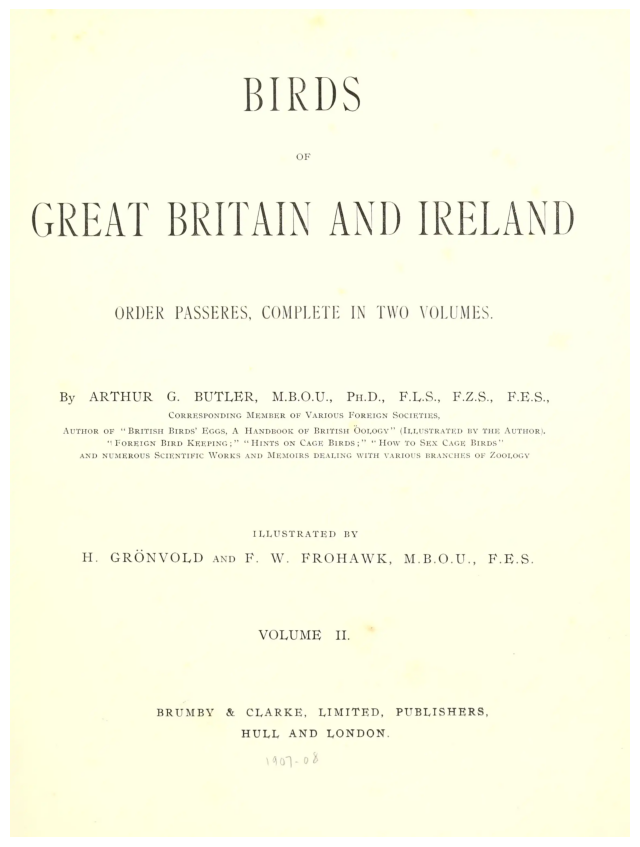

TESSERACT READ:
 BIRDS

OF

GREAT BRITAIN AND IRELAND

ORDER PASSERES, COMPLETE IN TWO VOLUMES.

By ARTHUR G. BUTLER, M.B.O.U., PH.D. F.LS., F.Z.S., F.E.S.,

CORRESPONDING MEMBER OF VARIOUS FOREIGN SOCIETIES,

AUTHOR OF “BRITISH BrrDS’ Eccs, A HANDBOOK OF BRITISH OoL0GY” (ILLUSTRATED BY THE AUTHOR).
‘(FOREIGN BIRD KEEPING;” ‘HINTS ON CAGE BiRDS;” ‘ How TO SEX CAGE BIRDS”
AND NUMEROUS SCIENTIFIC WORKS AND MEMOIRS DEALING WITH VARIOUS BRANCHES OF ZOOLOGY

ILLUSTRATED BY

H. GRONVOLD anv F. W. FROHAWK, M.B.O.U., F.E.S.
VOLUME II.

BRUMBY & CLARKE, LIMITED, PUBLISHERS,
HULL AND LONDON.


GROUND TRUTH:
 BIRDS

OF

GREAT BRITAIN AND IRELAND

ORDER PASSERES, COMPLETE IN TWO VOLUMES.

By ARTHUR G. BUTLER, M.B.O.U., PH.D., F.L.S., F.Z.S., F.E.S.,

CORRESPONDING MEMBER OF VARIOUS FOREIGN SOCIETIES,

AUTHOR OF "BRITISH BIRDS' EGGS, A HANDBOOK OF BRITISH ÖOLOGY" (ILLUSTRATED BY THE AUTHOR).
"FOREIGN BIRD KEEPING;" "HINTS ON CAGE BIRDS;" "HOW TO SEX CAGE BIRDS"
AND NUMBEROUS SCIENTIFIC WORKS AND ME

In [3]:
row = ds[pages[0]]
img = row["image"].convert("RGB")
ocr_text = pytesseract.image_to_string(img, lang="eng")

plt.figure(figsize=(8, 11)); plt.imshow(img); plt.axis("off"); plt.show()
print("TESSERACT READ:\n", ocr_text[:800])
print("\nGROUND TRUTH:\n", row["text"][:800])

In [4]:
import random
import time
import pandas as pd

def words(s):
    return s.split()

# Share of words that match the ground truth, in order (1.00 = identical). A rough score, not an official error rate.
def word_match(truth, read):
    return difflib.SequenceMatcher(None, words(truth), words(read), autojunk=False).ratio()

N = 10                                           # how many pages to score; raise it for a fuller picture
random.seed(42)
sample = random.sample(pages, min(N, len(pages)))   # random pages from both books

rows = []
for i in sample:
    row = ds[i]
    t0 = time.time()
    text = pytesseract.image_to_string(row["image"].convert("RGB"), lang="eng")
    rows.append({"idx": i, "PageID": row["PageID"], "book": row["BarCode"],
                 "word_match": round(word_match(row["text"], text), 3),
                 "seconds": round(time.time() - t0, 1)})
    print(f"{len(rows)}/{len(sample)} pages done", end="\r")

scores = pd.DataFrame(rows)
print(scores.drop(columns="idx").to_string(index=False))
print("\nMean word match:", round(scores.word_match.mean(), 3), "| median:", round(scores.word_match.median(), 3))

 PageID                   book  word_match  seconds
8966949 conchologiaiconi05reev       0.738      4.7
8992418 birdsofgreatbrit02butl       0.971      3.1
8992327 birdsofgreatbrit02butl       0.977      4.3
8967055 conchologiaiconi05reev       0.739      4.3
8992543 birdsofgreatbrit02butl       0.945      3.2
8992522 birdsofgreatbrit02butl       0.978      4.2
8992505 birdsofgreatbrit02butl       0.963      2.7
8992440 birdsofgreatbrit02butl       0.951      3.8
8967048 conchologiaiconi05reev       0.802      4.0
8992409 birdsofgreatbrit02butl       0.932      3.7

Mean word match: 0.9 | median: 0.948


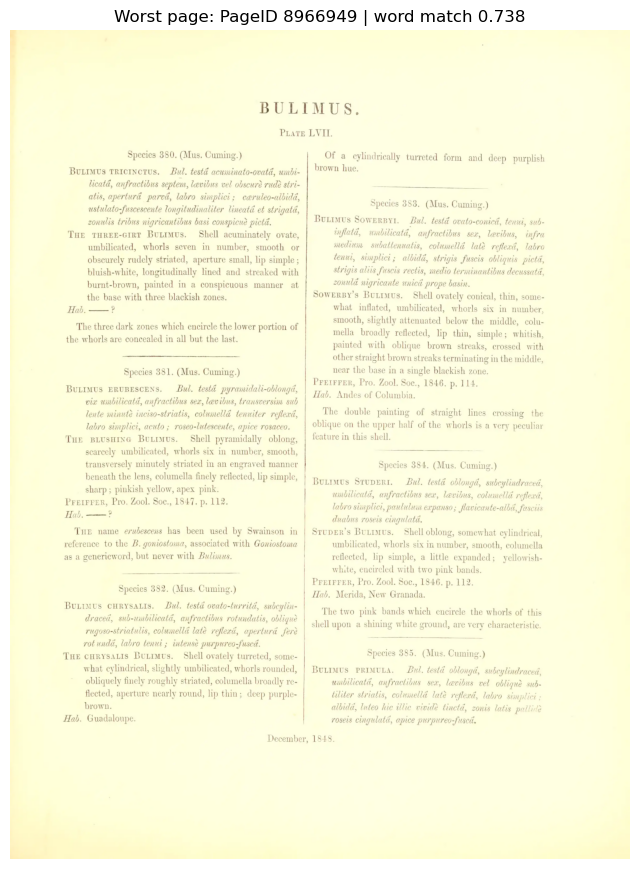

TESSERACT READ:
 BULIMUS.

Prats LVII.

Species 380. (Mus. Cuming.)

BuLruts Triemwctus. Bul. testd acuminato-ovatd, umbi-
licatd, anfractibus septem, levibus vel obscure rude stri-
atis, apertura pared, labro simplici; ca@ruleo-ulbida,
ustulato-fuscescente longitudinaliter lineatd et strigatd,
zonulis tribus nigricantibus basi conspicue picta.

THE THREE-GIRT Butimus. Shell acuminately ovate,
umbilicated, whorls seven in number, smooth or
obscurely rudely striated, aperture small, lip simple ;
bluish-white, longitudinally lined and streaked with
burnt-brown, painted in a conspicuous manner at
the base with three blackish zones.

Hab. E

The three dark zones which encircle the lower portion of
the whorls are concealed in all but the last.

Species 381. (Mus. Cuming.)

BuLIMUs ERUBESCENS. Bul. testd pyramid

GROUND TRUTH:
 BULIMUS.

PLATE LVII.

Species 380. (Mus. Cuming.)

BULIMUS TRICINCTUS. Bul. testâ acuminato-ovatâ, umbi‑
licatâ, anfractibus septem, Iœvibus vel obscurè rudè stri‑
a

In [5]:
# Look at the page Tesseract struggled with most
worst = scores.sort_values("word_match").iloc[0]
row = ds[int(worst.idx)]
img = row["image"].convert("RGB")
text = pytesseract.image_to_string(img, lang="eng")

plt.figure(figsize=(8, 11)); plt.imshow(img); plt.axis("off")
plt.title(f"Worst page: PageID {worst.PageID} | word match {worst.word_match}"); plt.show()
print("TESSERACT READ:\n", text[:800])
print("\nGROUND TRUTH:\n", row["text"][:800])